In [2]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import  seaborn as sns

df = pd.read_csv("../data/raw/ai4i2020.csv")
sns.set_theme(style="whitegrid")

Analyse the targert distribution

In [3]:
#count each target class
failure_counts = df["Machine failure"].value_counts()

print(failure_counts)

#Calculate percentages
failure_percentage = df["Machine failure"].value_counts(normalize=True)* 100

print("\nPercentage distribution:")
print(failure_percentage)

Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentage distribution:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


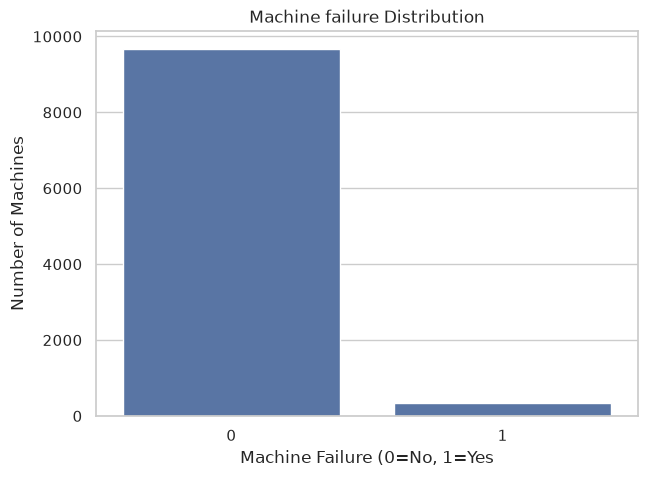

In [4]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x = "Machine failure")

plt.title("Machine failure Distribution")
plt.xlabel("Machine Failure (0=No, 1=Yes")
plt.ylabel("Number of Machines")
plt.show()

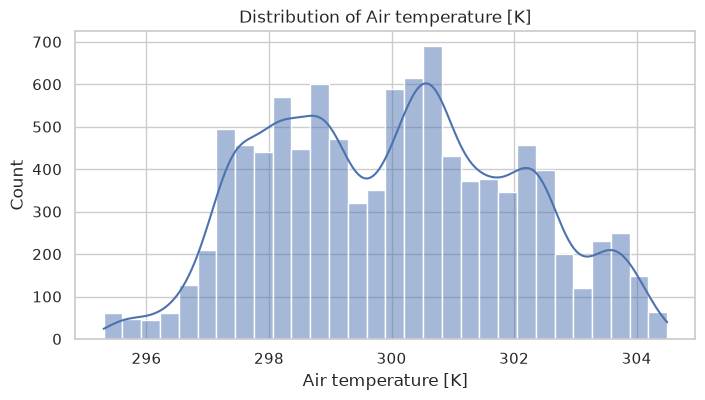

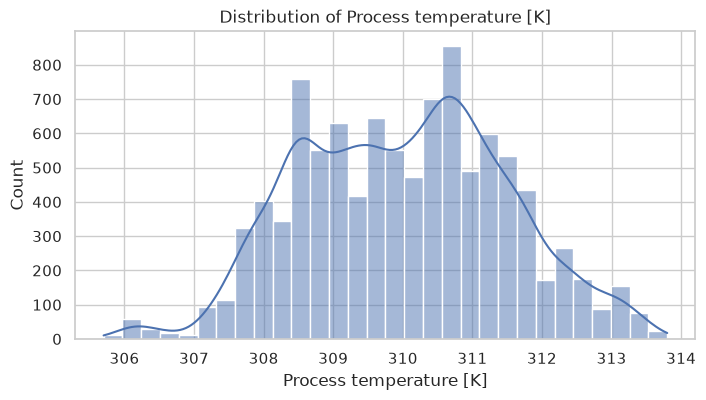

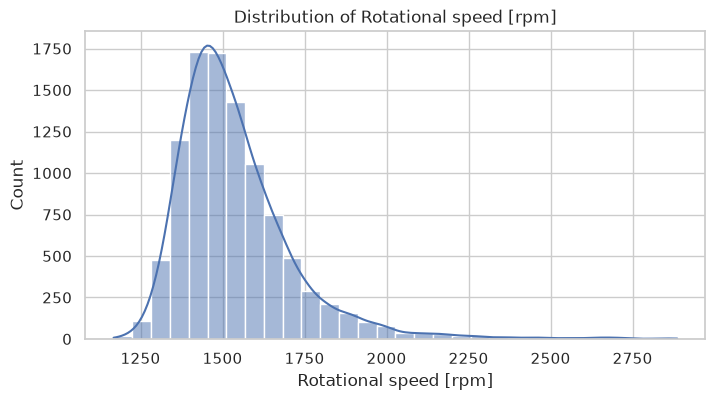

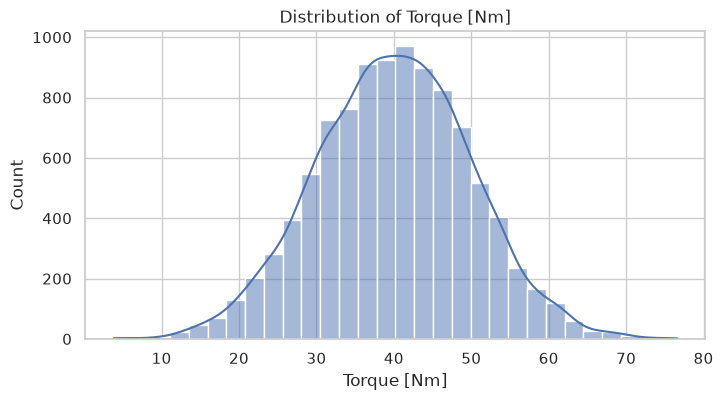

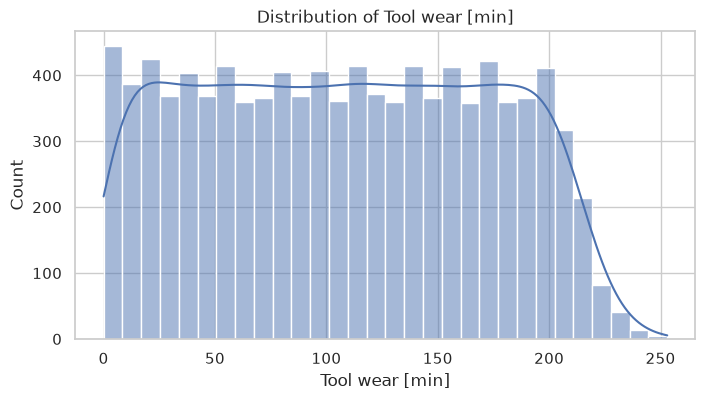

In [5]:
sensor_coloumns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
for coloumn in sensor_coloumns:
    plt.figure(figsize=(8,4))

    sns.histplot(
        data=df,
        x=coloumn,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {coloumn}")
    plt.show()


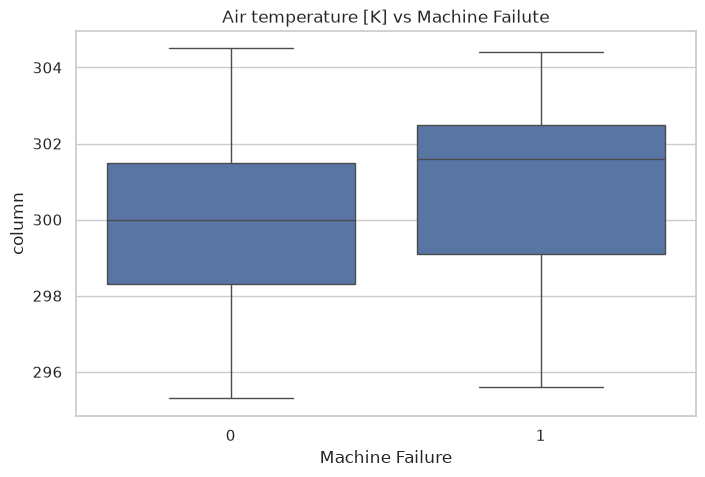

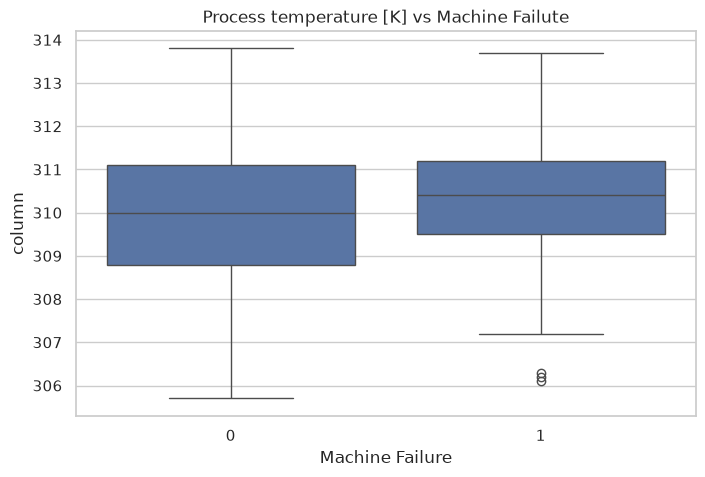

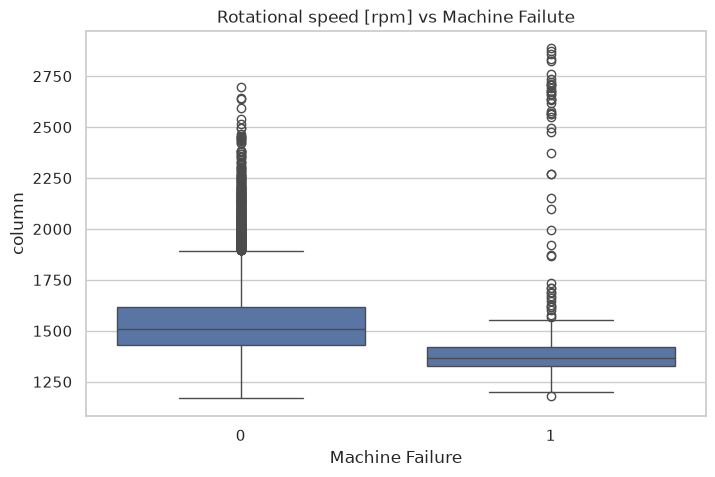

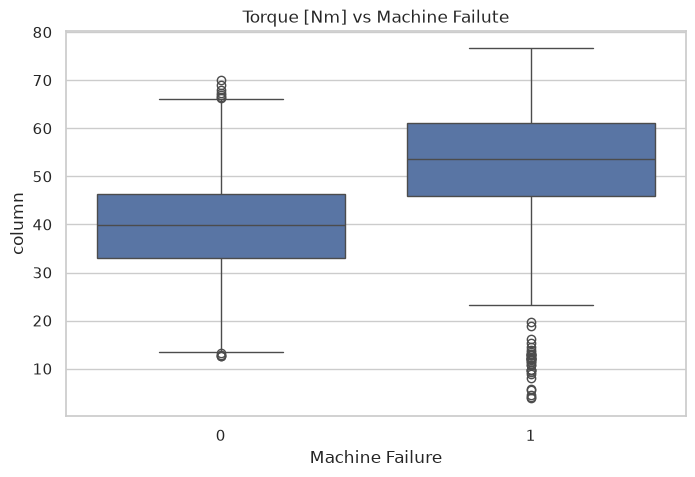

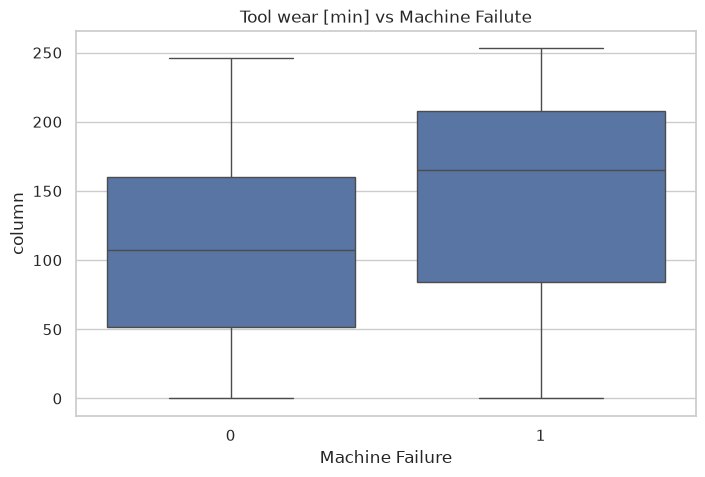

In [6]:
for coloumn in sensor_coloumns:
    plt.figure(figsize=(8,5))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=coloumn
    )

    plt.title(f"{coloumn} vs Machine Failute")
    plt.xlabel("Machine Failure")
    plt.ylabel("column")

    plt.show()

In [8]:
failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .agg(["count", "sum", "mean"])
)

failure_by_type["failure_percentage"] = (failure_by_type["mean"]*100)

print(failure_by_type)


      count  sum      mean  failure_percentage
Type                                          
H      1003   21  0.020937            2.093719
L      6000  235  0.039167            3.916667
M      2997   83  0.027694            2.769436


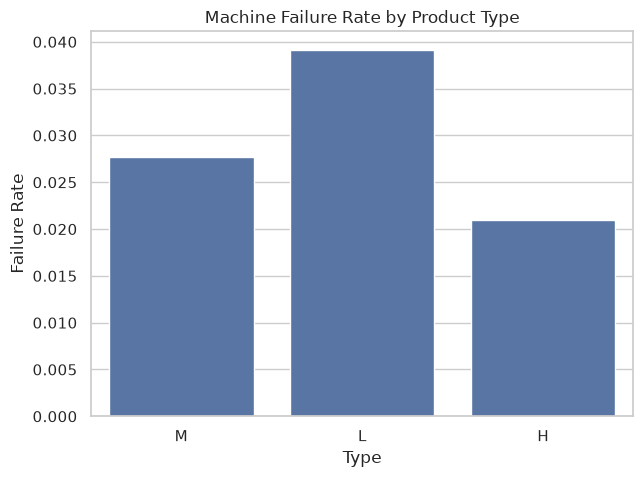

In [9]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=df,
    x="Type",
    y="Machine failure",
    errorbar=None
)

plt.title("Machine Failure Rate by Product Type")
plt.ylabel("Failure Rate")
plt.show()

In [10]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for column in sensor_columns:
    print(f"\n{column}")

    print(
        df.groupby("Machine failure")[column]
        .agg(["mean", "median", "std"])
    )


Air temperature [K]
                       mean  median       std
Machine failure                              
0                299.973999   300.0  1.990748
1                300.886431   301.6  2.071473

Process temperature [K]
                       mean  median       std
Machine failure                              
0                309.995570   310.0  1.486846
1                310.290265   310.4  1.363686

Rotational speed [rpm]
                        mean  median         std
Machine failure                                 
0                1540.260014  1507.0  167.394734
1                1496.486726  1365.0  384.943547

Torque [Nm]
                      mean  median        std
Machine failure                              
0                39.629655    39.9   9.472080
1                50.168142    53.7  16.374498

Tool wear [min]
                       mean  median        std
Machine failure                               
0                106.693717   107.0  62.945790
1          